## 1. Importation des bibliothèques fondamentales

- **Objectif** : Charger les librairies de base indispensables pour la manipulation des données (Pandas, NumPy) et la création de visualisations (Matplotlib, Seaborn).

In [98]:
# Importation des bibliothèques fondamentales
import matplotlib.pyplot as np
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print("✅ Bibliothèques importées avec succès !")

✅ Bibliothèques importées avec succès !


## 1.1 Ingestion des données brutes
Nous chargeons ici nos fichiers sources. 

In [99]:
Sales = pd.read_csv("Sales_cleaned_silver.csv")
print("Importation du fichier avec succès")

Importation du fichier avec succès


## 2. Configuration du Design System (Charte Graphique B2B)

- **Objectif** : Définir les variables globales de couleurs, les styles d'axes et la typographie pour garantir une identité visuelle professionnelle et cohérente sur tous les graphiques.

In [100]:
# ==========================================
# DESIGN SYSTEM / CHARTE GRAPHIQUE B2B
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Palette de couleurs sémantiques
PRIMARY_COLOR = "#1F4E79"    # Bleu marine corporate (barres principales, tendances)
ACCENT_COLOR = "#D35400"     # Orange corail / Ambre (mise en avant, alertes, records)
SECONDARY_COLOR = "#3498DB"  # Bleu clair / Turquoise (comparaisons, catégories)
GRAY_SLATE = "#7F8C8D"       # Gris ardoise (éléments secondaires)
TEXT_COLOR = "#2C3E50"       # Gris foncé / Noir doux pour les textes et titres
GRID_COLOR = "#E2E8F0"       # Gris très clair pour les grilles épurées

# Palette globale pour les graphiques multi-catégories (camemberts, barplots...)
COLOR_PALETTE = [PRIMARY_COLOR, ACCENT_COLOR, SECONDARY_COLOR, GRAY_SLATE]

# 2. Configuration globale de Matplotlib & Seaborn
sns.set_theme(style="whitegrid")  # Fond blanc avec grilles horizontales légères

# 3. Paramètres globaux (rcParams) - Tout s'applique automatiquement !
plt.rcParams.update({
    # Dimensions et résolution par défaut
    "figure.figsize": (12, 6),
    "figure.dpi": 300,
    
    # Polices et couleurs globales
    "font.family": "sans-serif",
    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    
    # Tailles et graisses automatiques (Finit les .fontsize à répéter !)
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    
    # Style de la grille et des axes
    "axes.edgecolor": GRID_COLOR,
    "axes.linewidth": 1.0,
    "grid.color": GRID_COLOR,
    "grid.linestyle": "--",
    "grid.alpha": 0.6,
    
    # Style des lignes par défaut (pour les lineplots)
    "lines.linewidth": 2.5,
    "lines.markersize": 7,
})

print("🎨 Design System complet appliqué avec succès !")

🎨 Design System complet appliqué avec succès !


## 3. Calcul des indicateurs clés (KPIs)

- **Objectif** : Extraire et quantifier les métriques essentielles à partir de la base de données propre (`Sales_cleaned_silver.csv`) pour évaluer la performance globale.
- **Indicateurs clés calculés** :
  - **Chiffre d'Affaires (CA) global**
  - **Panier moyen**
  - **Nombre d'entreprises / clients actifs**
  - **Nombre total de commandes**
  - **Nombre total d'articles vendus**
  - **Moyenne d'articles par commande**

In [101]:
print("Calculons le ca total...")
ca_total = Sales["TotalPrice"].sum()
print(f"le ca total est : {ca_total:,.2f} €")

Calculons le ca total...
le ca total est : 2,397,970.00 €


In [102]:
print("Calculons le panier moyen...")
panier_moyen = Sales["TotalPrice"].mean()
print(f"Le panier moyen est : {panier_moyen:,.2f} €")

Calculons le panier moyen...
Le panier moyen est : 2,299.11 €


In [103]:
print("Calculons le nombre de commandes uniques...")
commandes_unique = Sales["OrderID"].nunique()
print(f"Le nombre de commandes uniques est : {commandes_unique}")

Calculons le nombre de commandes uniques...
Le nombre de commandes uniques est : 500


In [104]:
print("Calculons le nombre total de lignes de commandes...")
commandes_total = Sales["OrderID"].count()
print(f"Le nombre total de commandes est : {commandes_total}")

Calculons le nombre total de lignes de commandes...
Le nombre total de commandes est : 1043


In [105]:
print("Calculons la quantité moyenne d'articles par commande...")
quantite_moyenne = Sales["Quantity"].mean()
print(f"La quantité moyenne d'articles par commande est : {quantite_moyenne:,.2f}")

Calculons la quantité moyenne d'articles par commande...
La quantité moyenne d'articles par commande est : 2.98


In [106]:
print("Calculons le nombre d'entreprises clientes uniques...")
nb_entreprises = Sales["CompanyName"].nunique()
print(f"Le nombre total d'entreprises uniques est : {nb_entreprises}")

Calculons le nombre d'entreprises clientes uniques...
Le nombre total d'entreprises uniques est : 8


In [107]:
# Création d'un dictionnaire regroupant nos indicateurs clés
kpis_Sales = {
    "indicateurs_clés" : [
        "ca_total",
        "panier_moyen",
        "commandes_unique",
        "commandes_total",
        "quantite_moyenne",
        "nb_entreprises"
    ],

    "valeurs" : [
        f"{ca_total:,.2f} €",
        f"{panier_moyen:,.2f} €",
        f"{commandes_unique}",
        f"{commandes_total}",
        f"{quantite_moyenne:,.2f}",
        f"{nb_entreprises}"
    ],
}
Sales_kpis_globeaux = pd.DataFrame(kpis_Sales)
# Affichage du tableau récapitulatif
Sales_kpis_globeaux

,indicateurs_clés,valeurs
0,ca_total,"2,397,970.00 €"
1,panier_moyen,"2,299.11 €"
2,commandes_unique,500
3,commandes_total,1043
4,quantite_moyenne,2.98
5,nb_entreprises,8


## 4. Visualisations Graphiques

### 4.1. Évolution temporelle du Chiffre d'Affaires
- **Objectif** : Analyser la dynamique des ventes au fil du temps (par mois/trimestre) afin d'identifier les tendances de fond, la saisonnalité et les pics d'activité.
- **Indicateur visualisé** : Chiffre d'affaires cumulé par période.

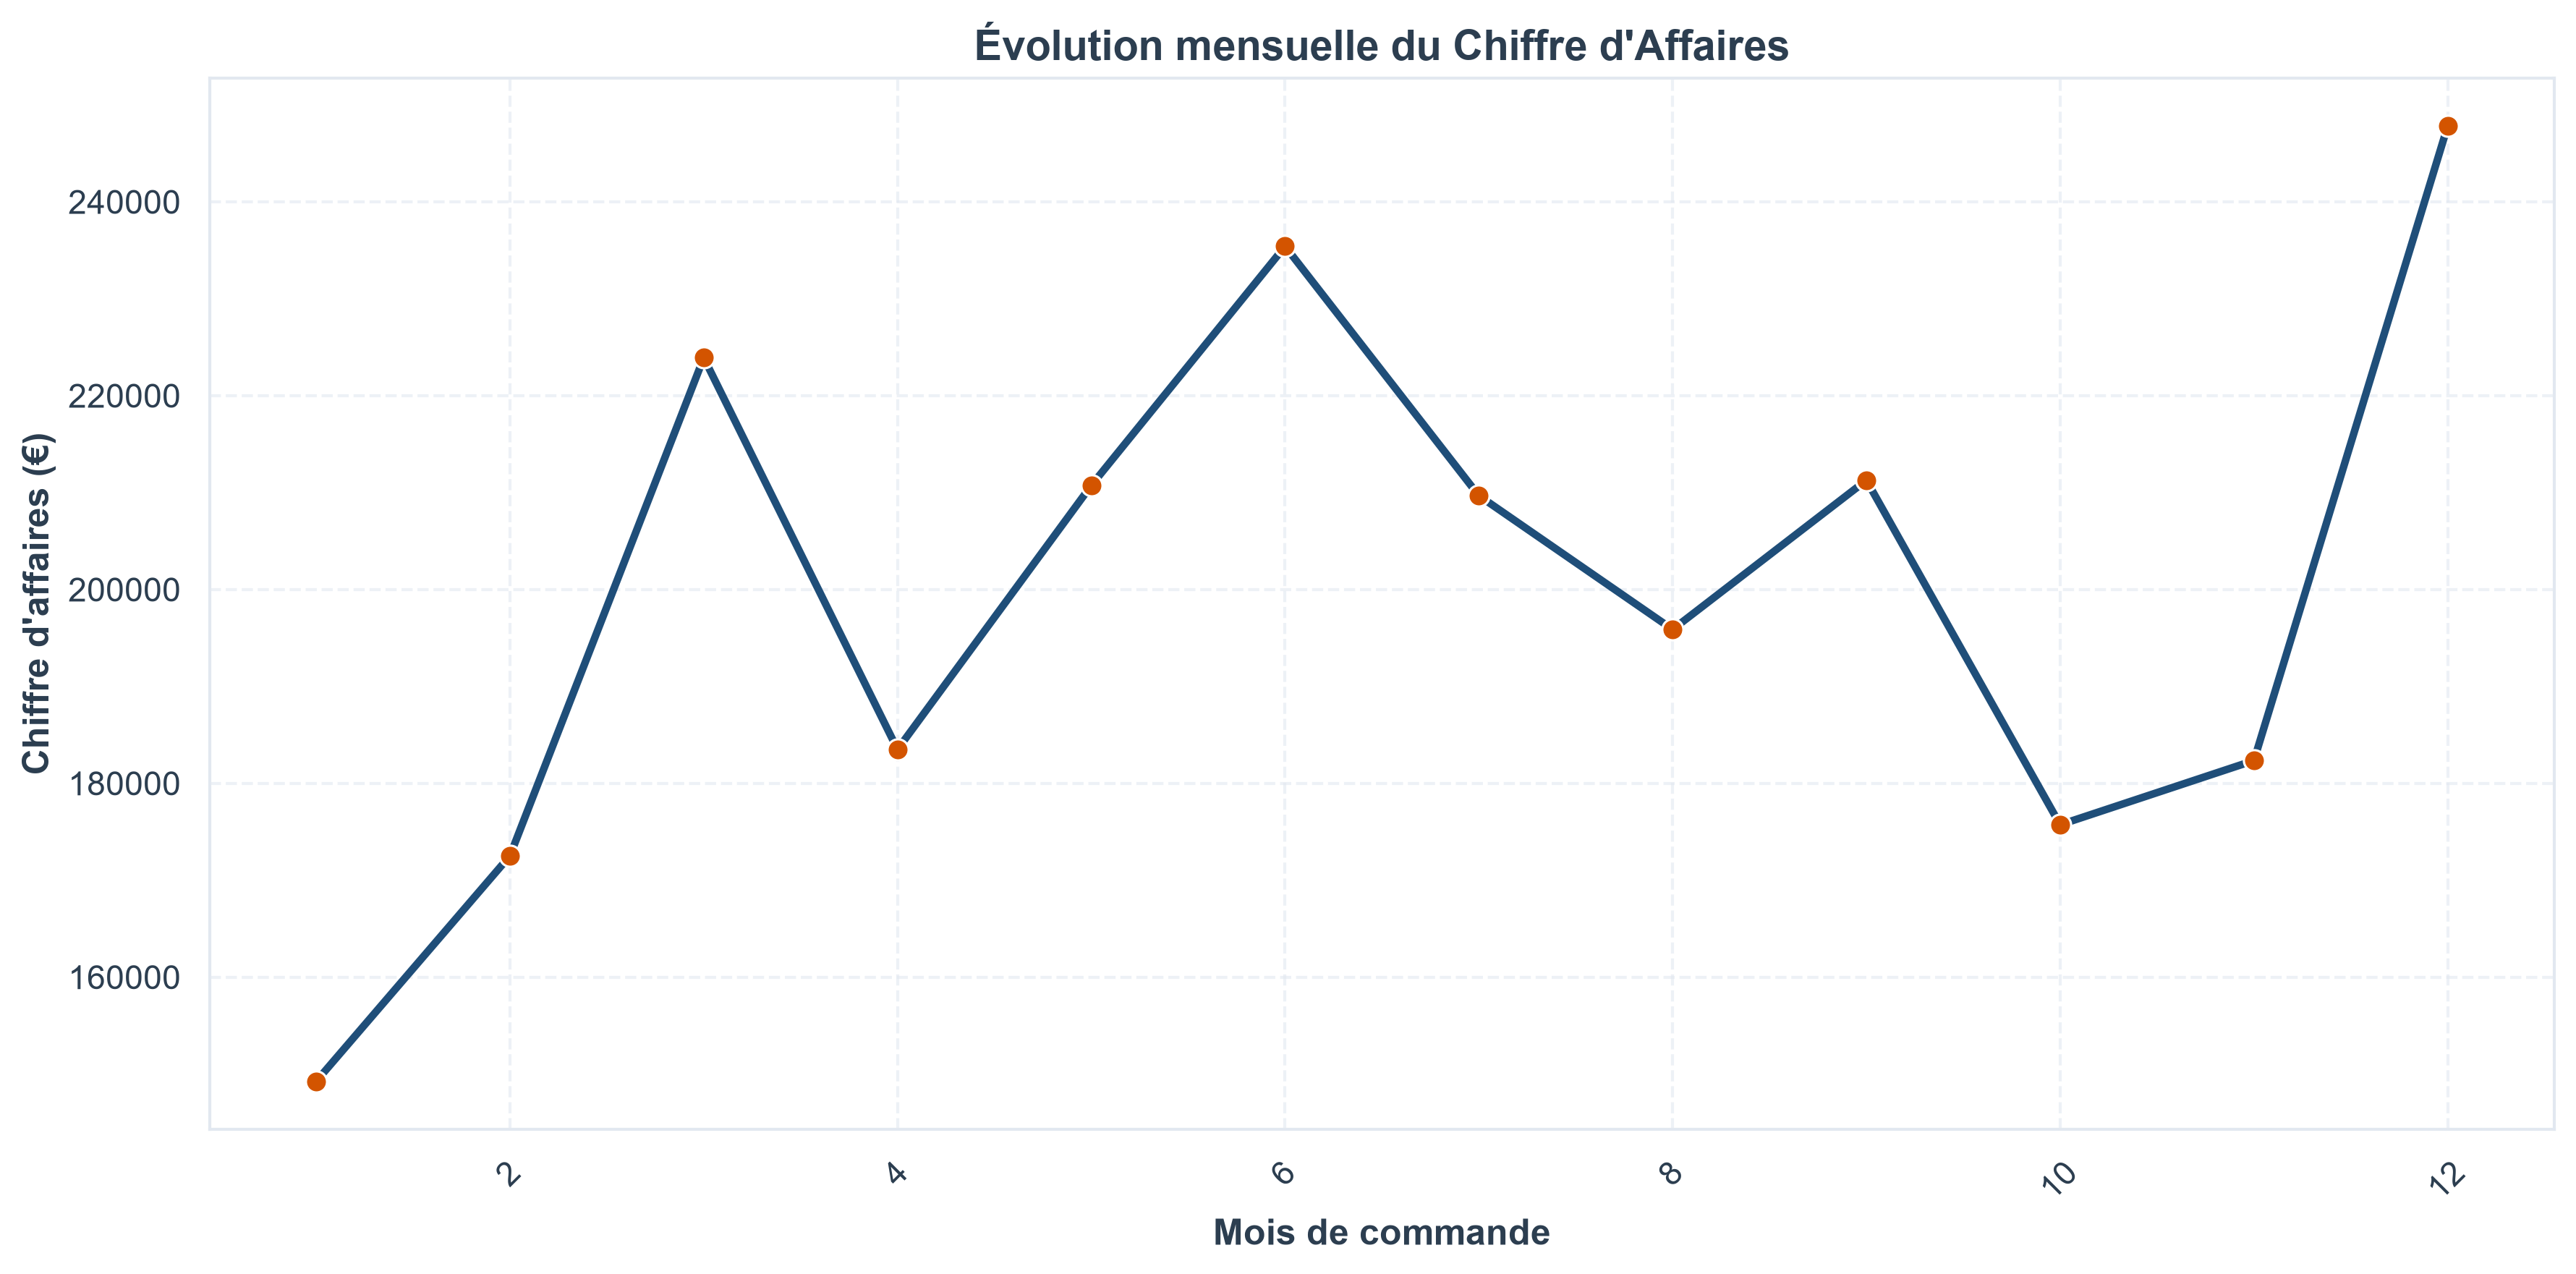

In [108]:
ca_total_mois = Sales.groupby ("OrderMonth")["TotalPrice"].sum().reset_index()
# Création de la figure (prend automatiquement la taille (12, 6) et le DPI de 300 définis dans rcParams)
plt.figure()

# Tracé du graphique (on ne garde que l'essentiel : les données, la couleur principale et le marqueur)
sns.lineplot(
    data=ca_total_mois,
    x="OrderMonth",
    y="TotalPrice",
    color=PRIMARY_COLOR,
    marker="o",
    markerfacecolor=ACCENT_COLOR
)
# Titre et labels (la taille, la graisse 'bold' et la couleur s'appliquent toutes seules !)
plt.title("Évolution mensuelle du Chiffre d'Affaires")
plt.xlabel("Mois de commande")
plt.ylabel("Chiffre d'affaires (€)")

# Rotation indispensable pour la lisibilité des mois
plt.xticks(rotation=45)

# Pas besoin de coder la grille ou les épaisseurs de traits : c'est déjà géré en amont.
plt.tight_layout()
plt.show()

### 💡 Analyse de la saisonnalité et des tendances mensuelles du Chiffre d'Affaires

L'observation de l'évolution mensuelle met en évidence une **dynamique annuelle irrégulière**, rythmée par plusieurs phases de pics et de creux significatifs :

* **Les pics de performance (Moments forts) :**
  * **Décembre (Mois 12) :** C'est incontestablement le mois le plus prolifique de l'année, dépassant les 240 000 €, ce qui confirme un effet fort de fin d'année (saisonnalité des fêtes / B2B).
  * **Juin (Mois 6) :** Le deuxième grand sommet de l'année, frôlant les 240 000 €.
  * **Mars (Mois 3) :** Un premier pic notable au-dessus de 220 000 €, marquant la fin du premier trimestre.

* **Les périodes de creux et de repli :**
  * **Début d'année (Mois 1) :** Un démarrage bas (autour de 150 000 €) avant une remontée progressive.
  * **Le creux du Printemps (Mois 4) :** Une chute brutale après le pic de mars, ramenant le CA sous les 185 000 €.
  * **La longue période de transition (Mois 7 à Mois 11) :** Malgré un léger sursaut au mois 9, cette période globale est caractérisée par des niveaux plus bas et un plancher atteint aux mois 10 et 11 (sous les 180 000 €) avant l'accélération finale de décembre.

### 4.2. Top des catégories / produits les plus performants
- **Objectif** : Mettre en évidence les segments de produits qui génèrent le plus de chiffre d'affaires et pèsent le plus lourd dans l'activité B2B.
- **Indicateur visualisé** : CA total par catégorie ou produit (affichage en barres horizontales).

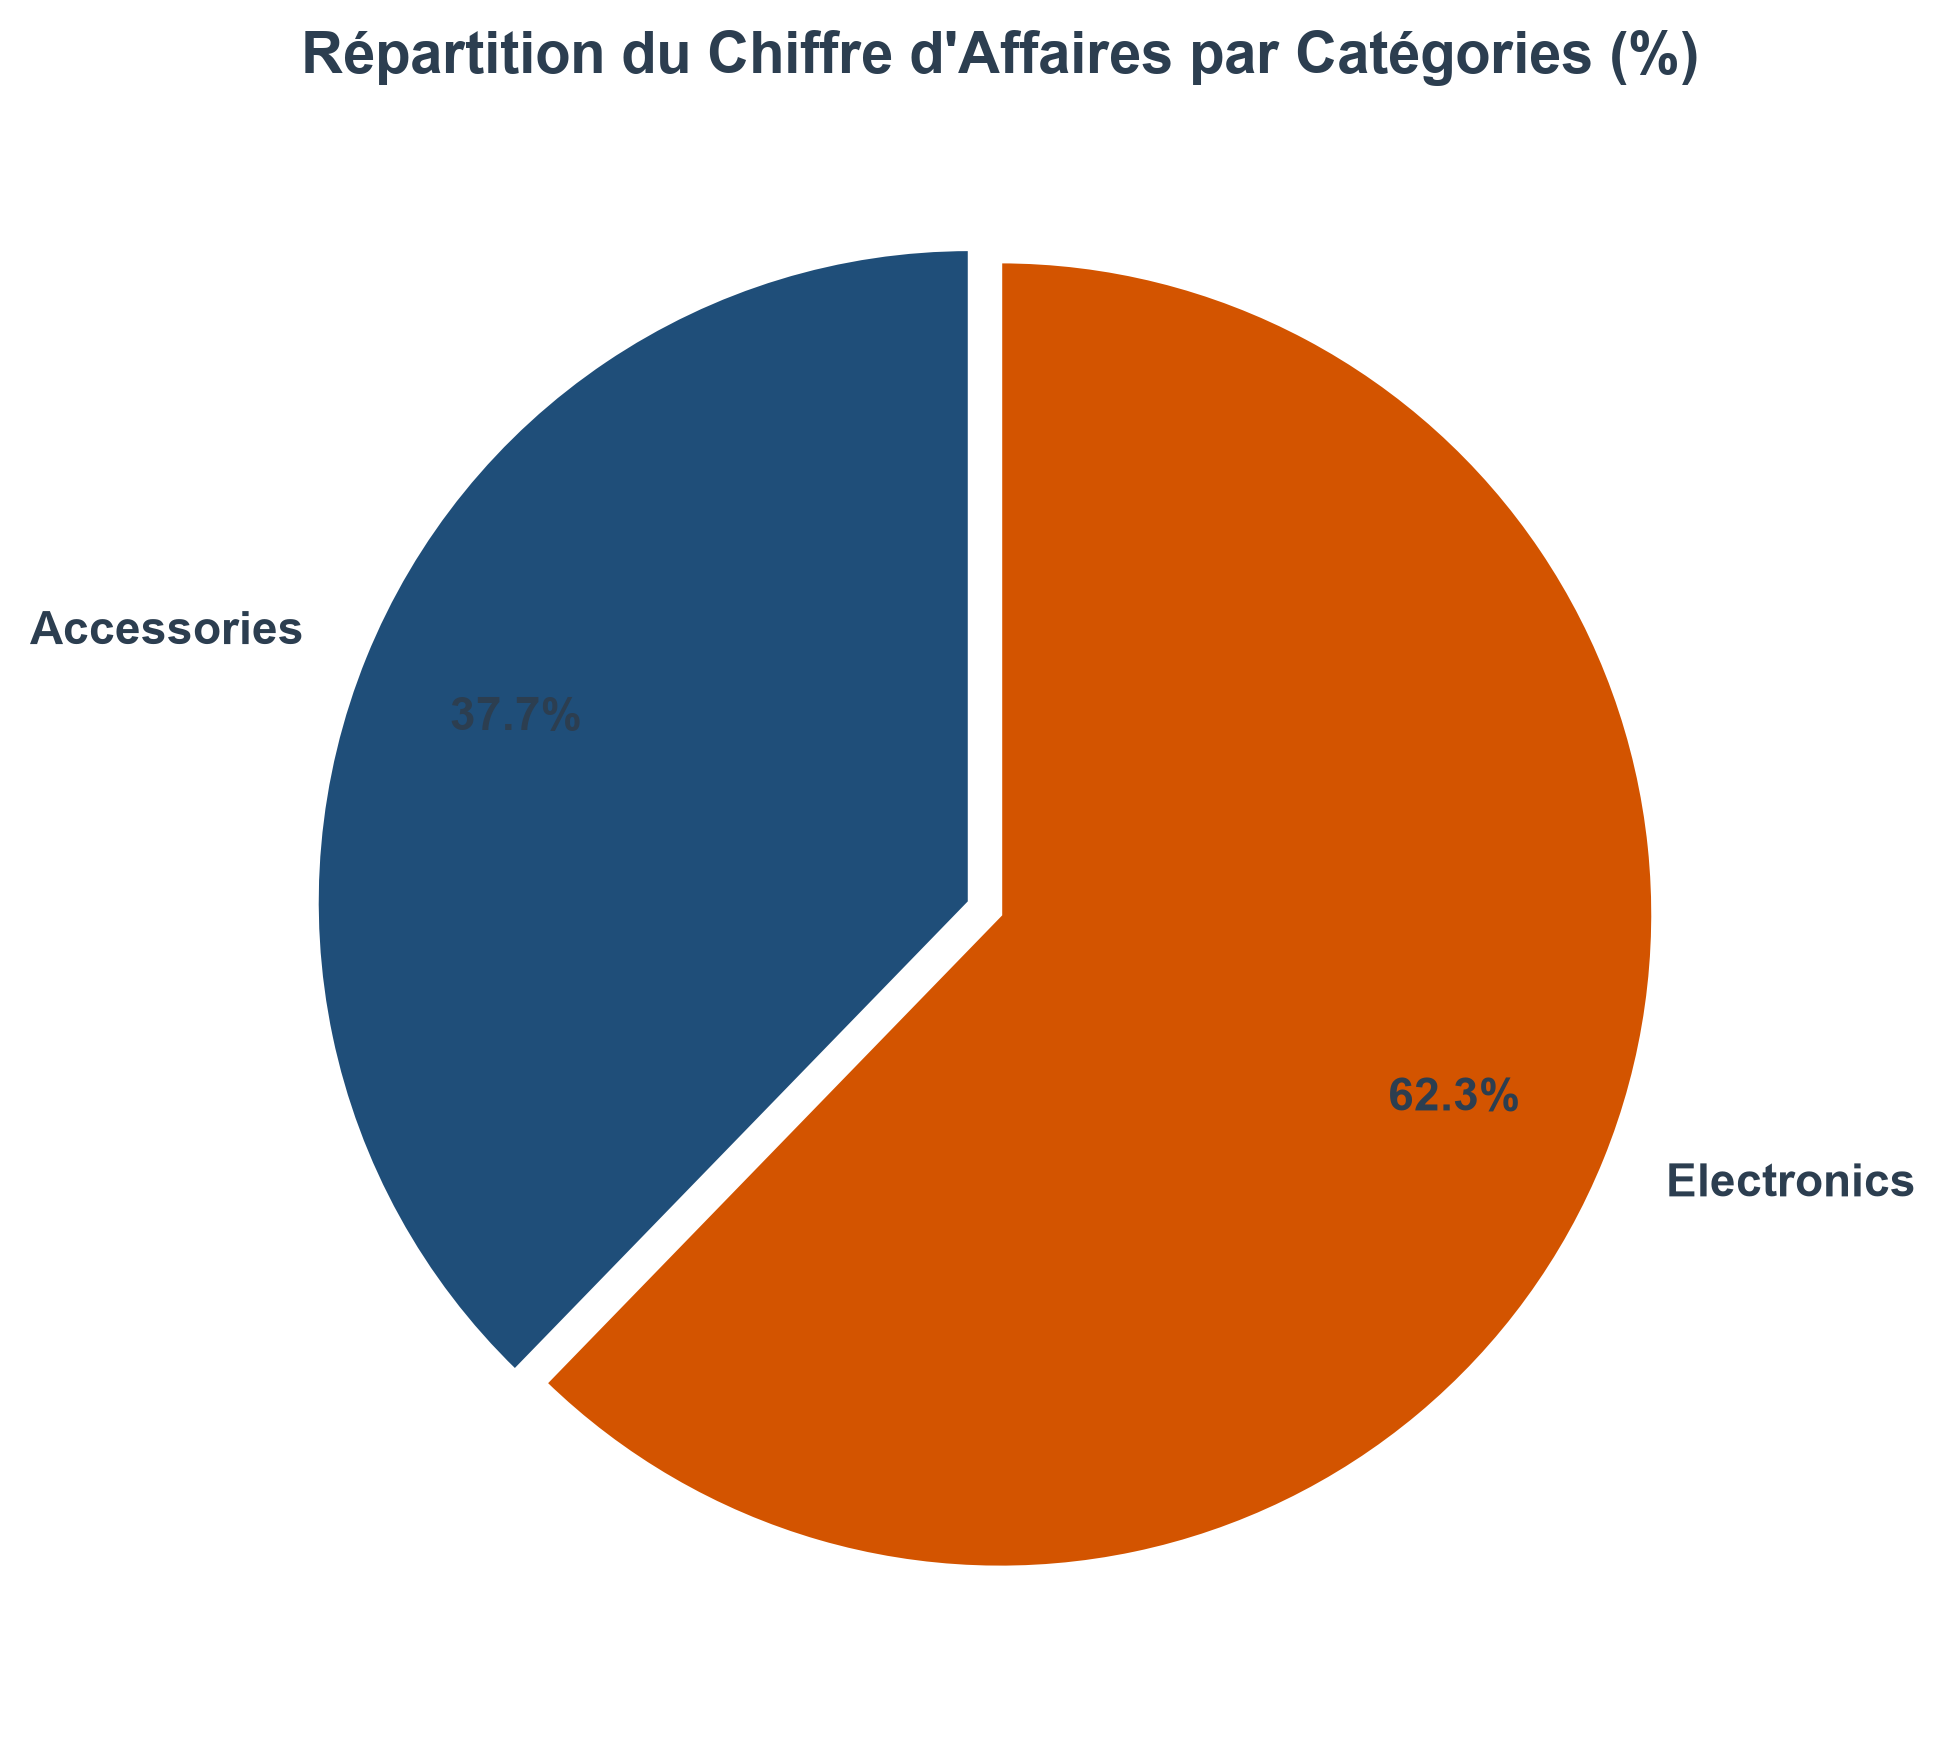

In [109]:
# Préparation des données (spécifique à l'analyse)
ca_total_categories = Sales.groupby("Category")["TotalPrice"].sum().reset_index()

# Choix ponctuel : décaler légèrement la première tranche pour l'isoler visuellement
mon_decalage = [0.05, 0] 

# Création de la figure (prend automatiquement la taille (12, 6) du rcParams)
plt.figure()

plt.pie(
    ca_total_categories["TotalPrice"],
    labels=ca_total_categories["Category"],
    autopct='%1.1f%%',
    startangle=90,
    colors=COLOR_PALETTE[:2],    # On pioche automatiquement les 2 premières couleurs de notre charte !
    explode=mon_decalage,        # Logique locale (propre à ce graphique)
    pctdistance=0.75,
    textprops={'weight': 'bold'} # La taille s'adapte, on garde juste le 'bold' si besoin
)

# Le titre récupère sa taille (14) et son gras (bold) directement du rcParams
plt.title("Répartition du Chiffre d'Affaires par Catégories (%)")

plt.tight_layout()
plt.show()

### 💡 Analyse de la répartition du Chiffre d'Affaires par Catégories

L'analyse de la part de marché en valeur met en lumière la structure des ventes par grandes familles de produits :

* **L'Électronique au cœur de la performance :** La catégorie *Electronics* domine largement avec **62,3 %** du chiffre d'affaires total, s'imposant comme le véritable moteur financier de l'entreprise.
* **Le rôle complémentaire des Accessoires :** La catégorie *Accessories* représente **37,7 %** du chiffre d'affaires, constituant un volume d'affaires important mais secondaire.
* **Piste explicative (Prix unitaires) :** Cette surreprésentation de l'électronique en valeur s'explique logiquement par un prix unitaire et un panier moyen nettement plus élevés sur cette gamme de produits par rapport aux accessoires.

### 4.3. Répartition géographique du Chiffre d'Affaires
- **Objectif** : Cartographier et comparer la performance des ventes par région ou par pays client.
- **Indicateur visualisé** : Part du CA global par zone géographique.

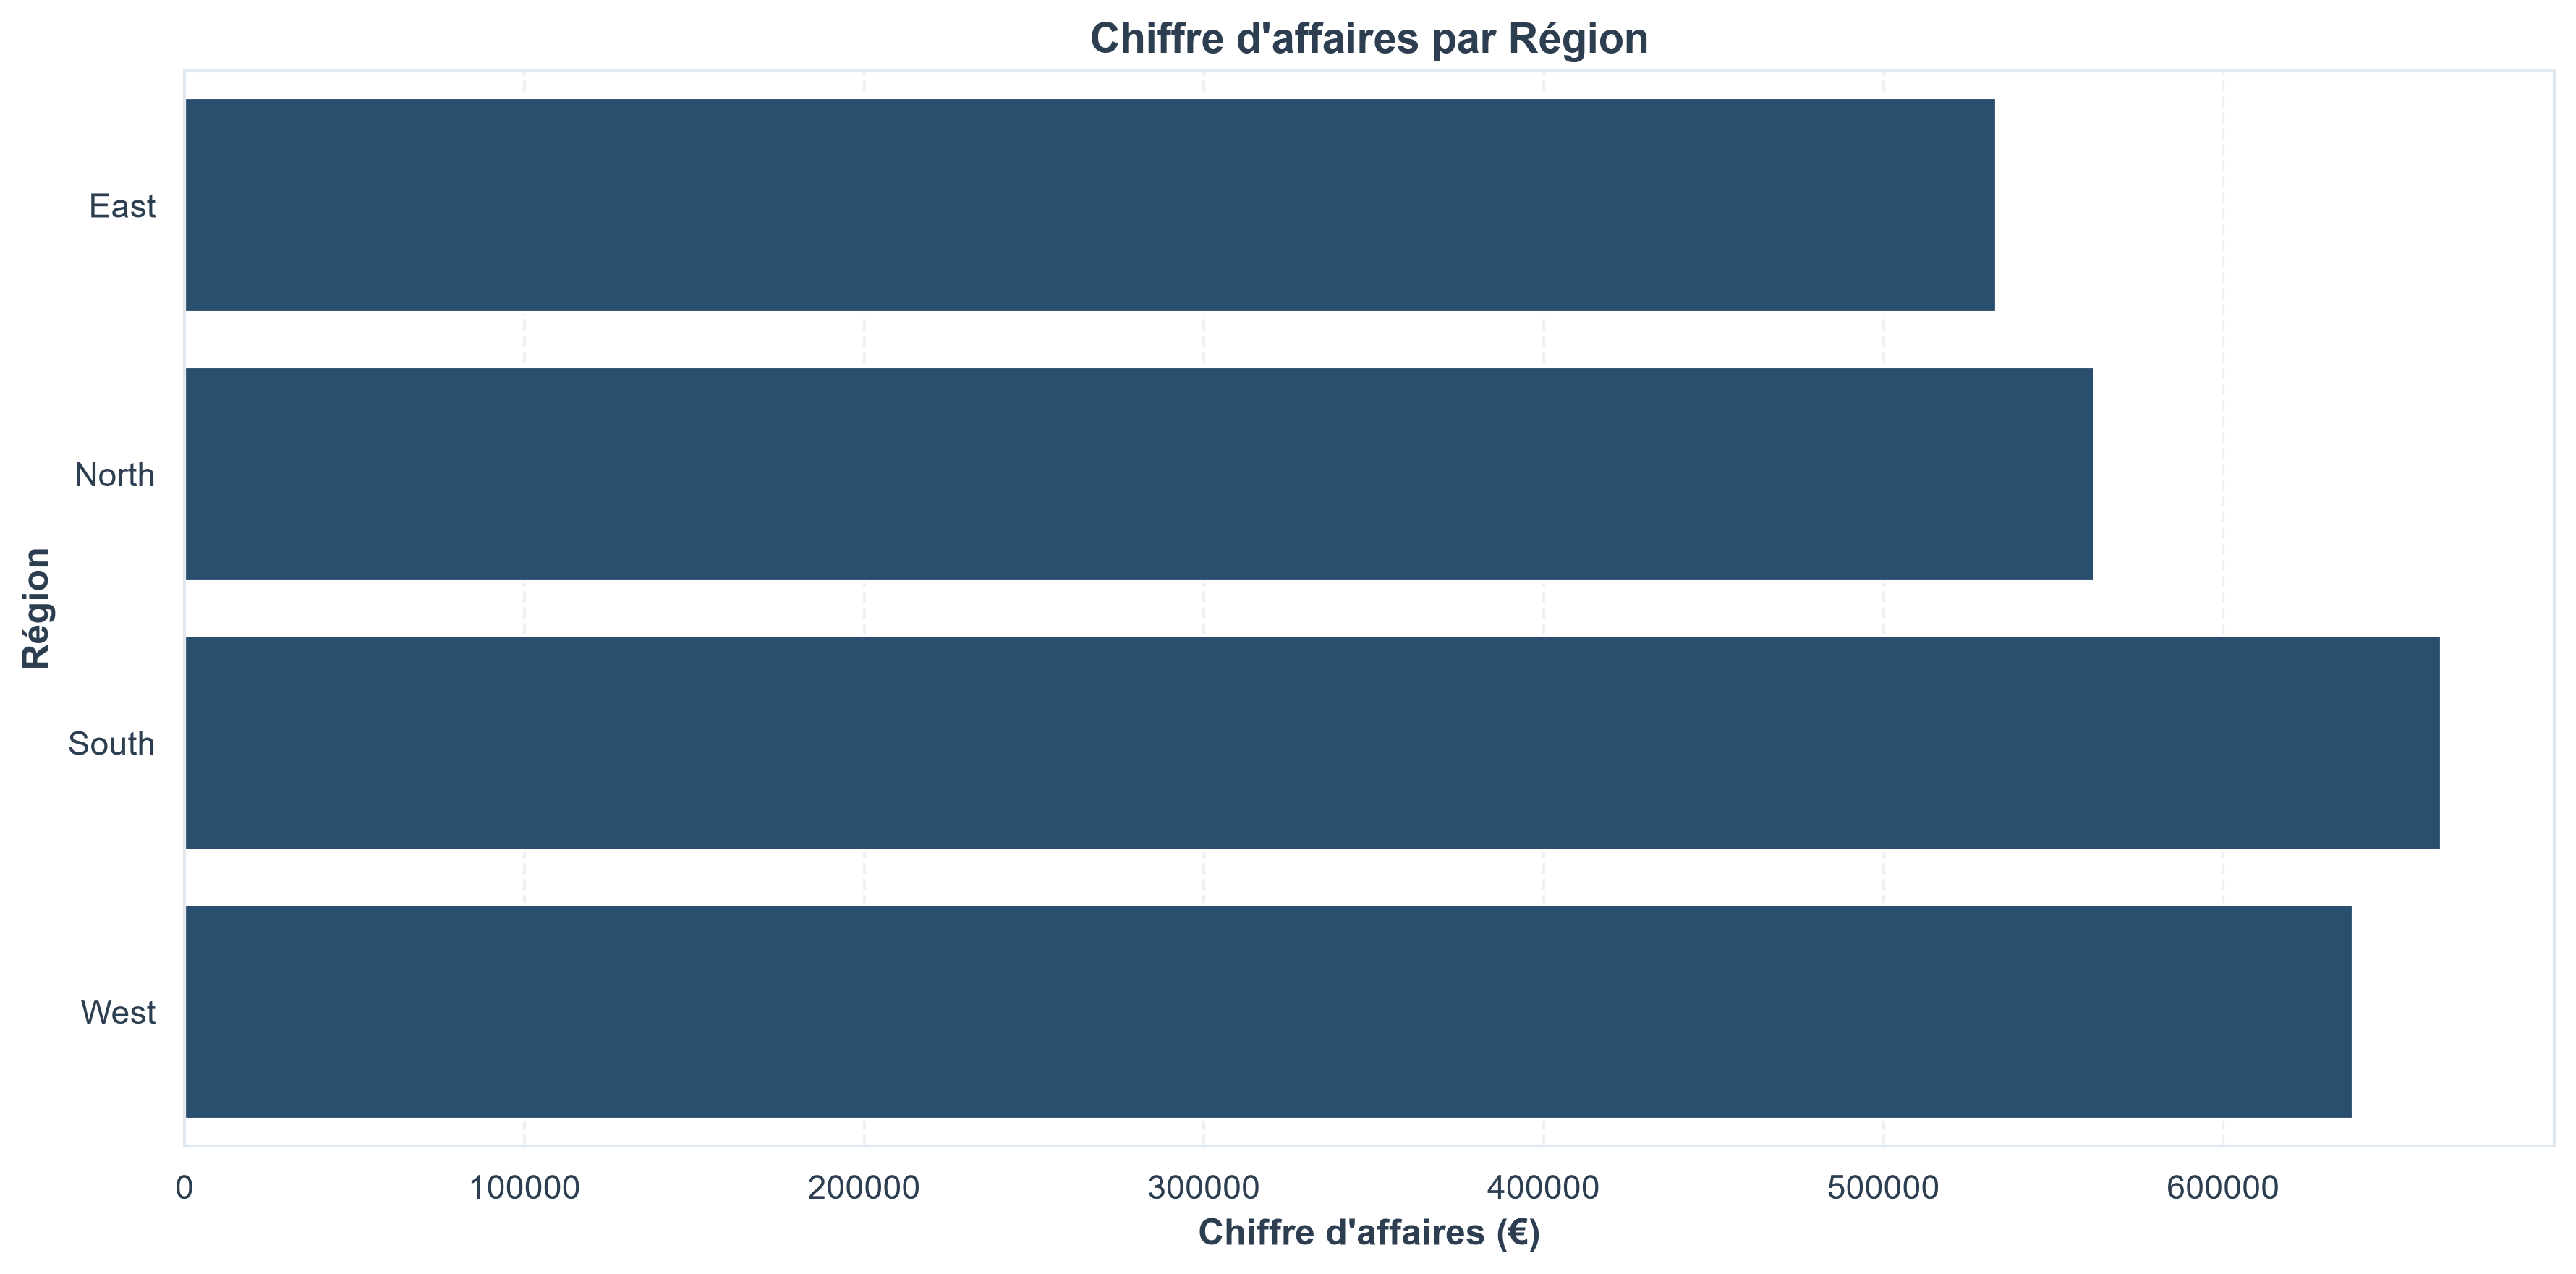

In [110]:
# (Petite suggestion : renomme ta variable en ca_total_regions pour que ce soit plus clair)
ca_total_regions = Sales.groupby("RegionName")["TotalPrice"].sum().reset_index()

# Création de la figure
plt.figure()

# Tracé horizontal : on inverse x et y
sns.barplot(
    data=ca_total_regions,
    x="TotalPrice",      # Le chiffre d'affaires passe sur l'axe horizontal (X)
    y="RegionName",      # Les régions passent sur l'axe vertical (Y)
    color=PRIMARY_COLOR
)

# Titre et labels ajustés au sens du graphique
plt.title("Chiffre d'affaires par Région")
plt.xlabel("Chiffre d'affaires (€)")
plt.ylabel("Région")

plt.tight_layout()
plt.show()

### 💡 Analyse de la répartition géographique du Chiffre d'Affaires

L'analyse par région montre une activité commerciale globalement bien équilibrée sur le territoire, l'ensemble des zones dépassant la barre des 500 000 € de chiffre d'affaires. On distingue toutefois deux dynamiques principales :

* **Les locomotives (Le fer de lance) :** Les régions **South** (en tête) et **West** portent la majeure partie de la performance commerciale, affichant les volumes de chiffre d'affaires les plus élevés (dépassant ou frôlant les 640 000 € - 660 000 €).
* **Les zones secondaires mais solides :** Les régions **North** et **East** affichent des contributions plus modérées (au-dessus de 500 000 €), constituant un socle d'activité stable mais avec un potentiel de croissance à aller chercher.

### 4.4. Distribution des montants de commandes (Panier)
- **Objectif** : Étudier la dispersion des montants de commandes pour comprendre la structure de la facturation (dominance de petits paniers vs gros volumes).
- **Indicateur visualisé** : Distribution statistique et densité des montants de commandes.

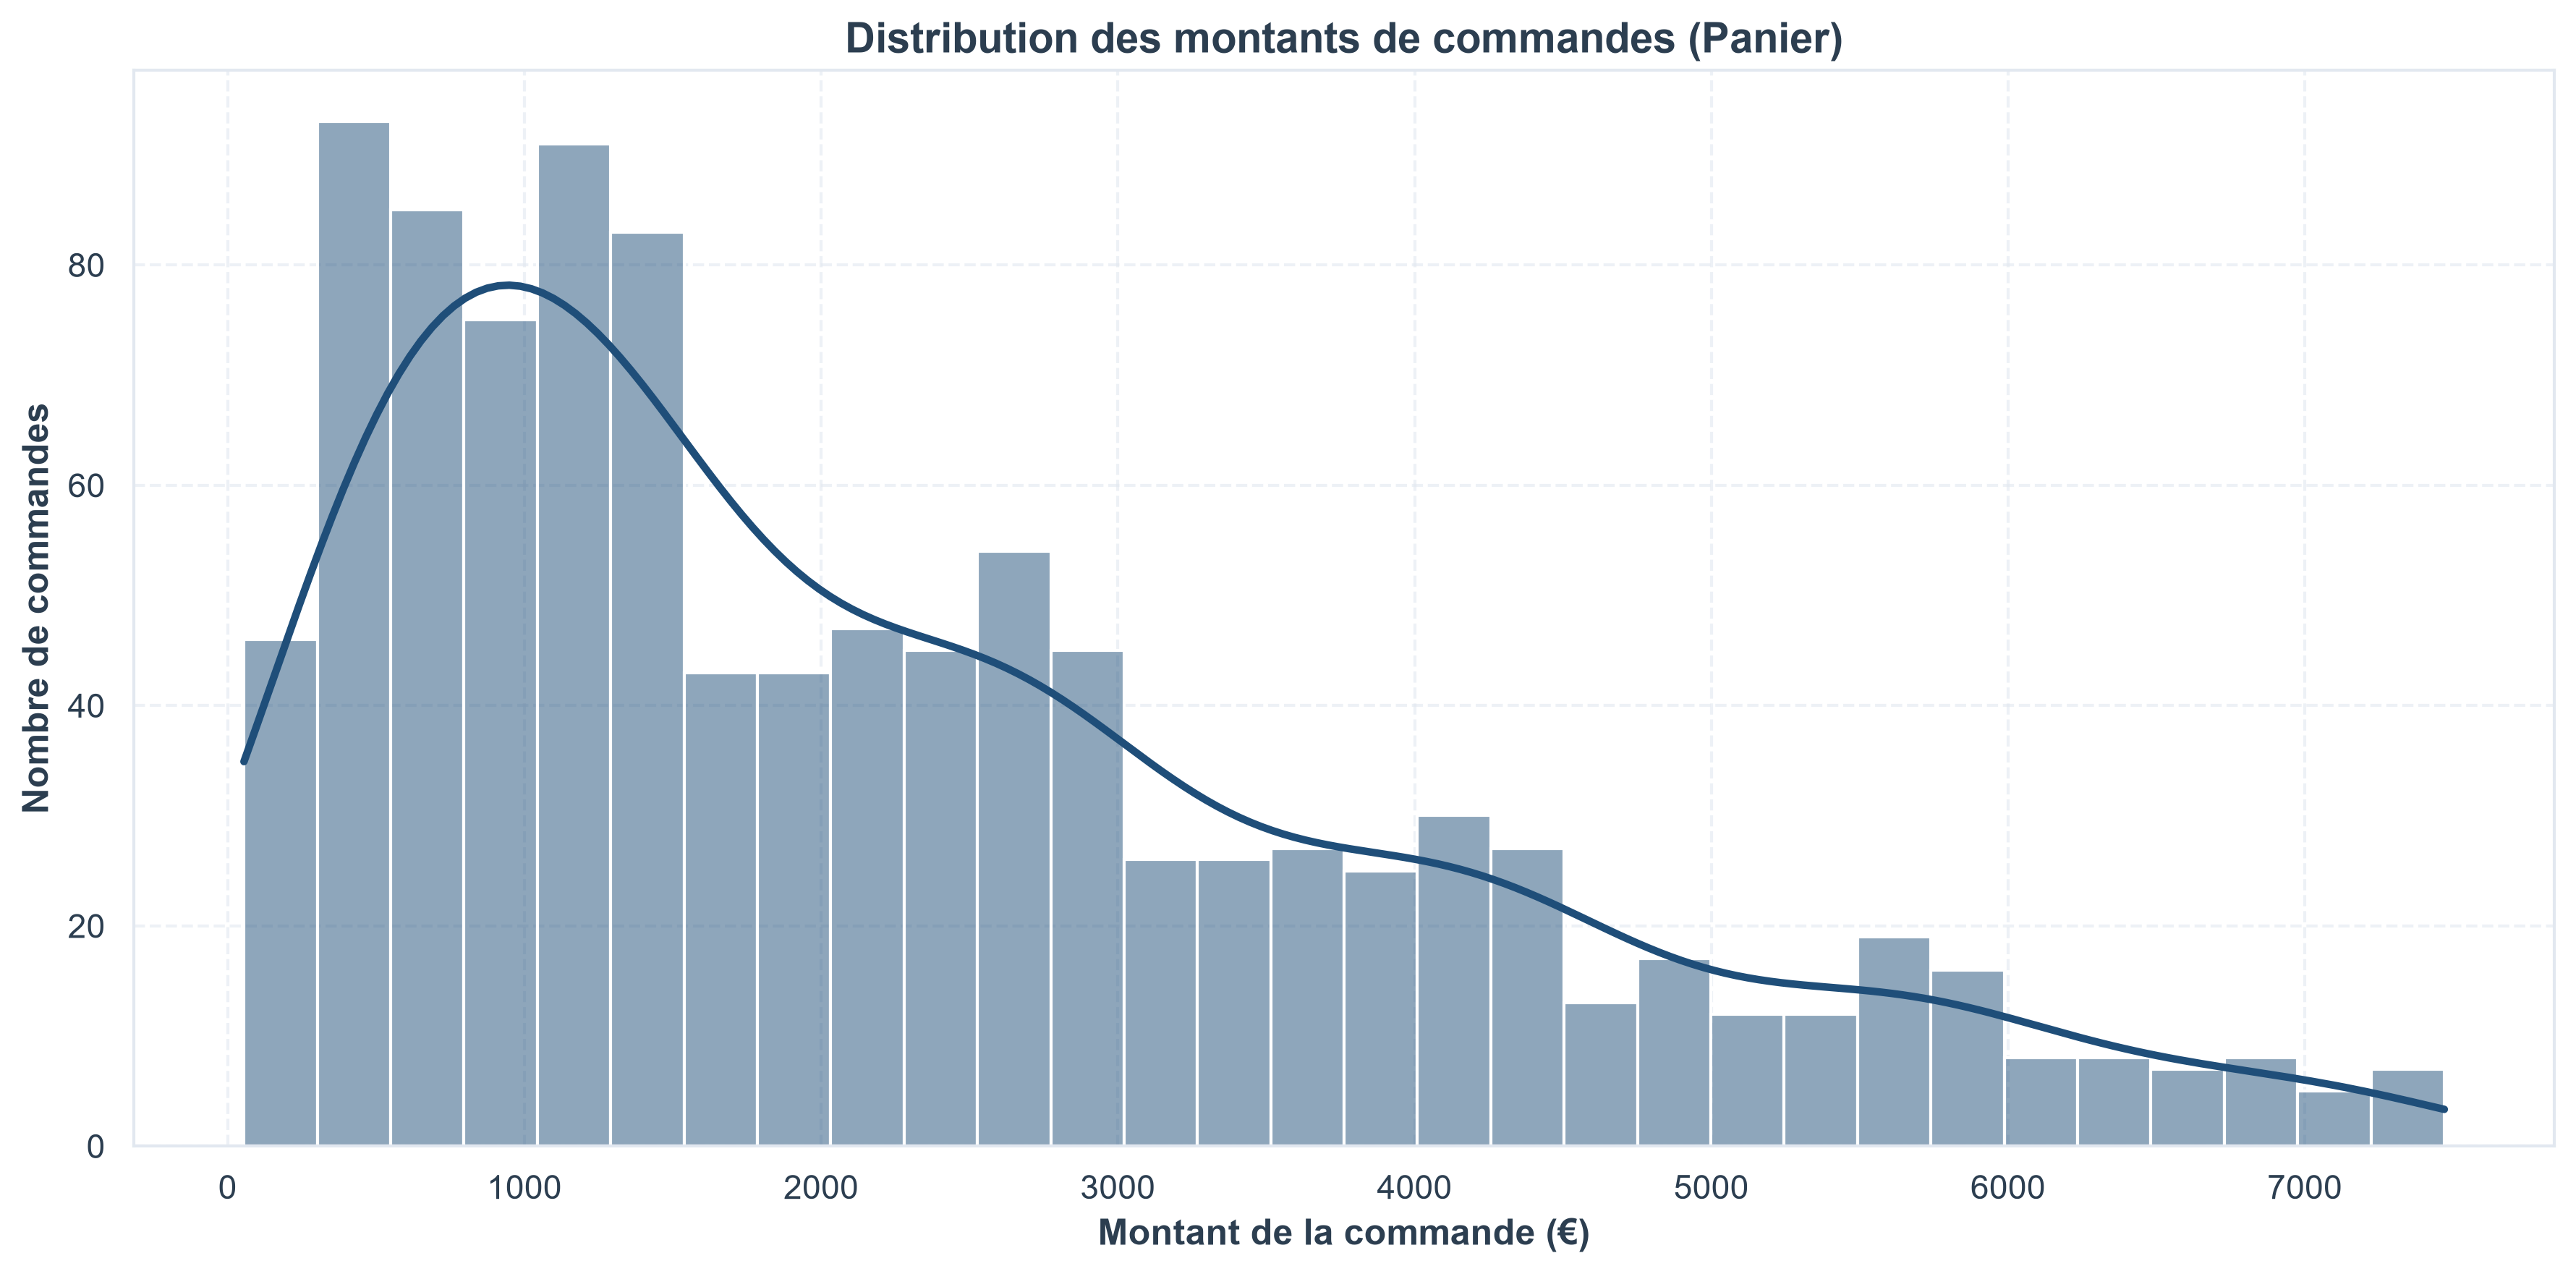

In [111]:
# Création de la figure
plt.figure()

# Tracé de l'histogramme avec la courbe de densité
sns.histplot(
    data=Sales,
    x="TotalPrice",         # La variable numérique dont on étudie la distribution
    color=PRIMARY_COLOR,    # Ton bleu marine corporate
    kde=True,               # Ajoute la courbe de densité lissée
    bins=30                 # Nombre de tranches (tu peux ajuster si besoin)
)

# Titre et labels
plt.title("Distribution des montants de commandes (Panier)")
plt.xlabel("Montant de la commande (€)")
plt.ylabel("Nombre de commandes")

plt.tight_layout()
plt.show()

### 💡 Analyse de la distribution des montants de commandes (Panier)

L'histogramme et la courbe de densité mettent en évidence la structure détaillée de la facturation et du panier d'achat :

* **Forte concentration sur les paniers intermédiaires et bas :** On observe un volume de commandes très important sur les tranches basses et moyennes (notamment entre 500 € et 1 500 €), ce qui montre un flux régulier de transactions.
* **Une asymétrie caractéristique (Longue traîne) :** À l'inverse, les montants les plus élevés (allant jusqu'à plus de 7 000 €) affichent un nombre de commandes extrêmement faible, illustrant des achats exceptionnels ou de grands comptes.
* **Piste d'approfondissement (Loi de Pareto) :** Cette répartition dissymétrique invite à creuser davantage pour mesurer précisément la contribution de ces différents segments au chiffre d'affaires global (notamment via une analyse de type Pareto / 80-20 pour identifier la part exacte portée par nos plus gros paniers).

### 4.5. Distribution des prix unitaires (`UnitPrice`)
- **Objectif** : Analyser la structure du catalogue de produits pour identifier le positionnement des prix (dominance de produits d'appel économiques vs produits à forte valeur ajoutée).
- **Indicateur visualisé** : Distribution statistique et densité des prix unitaires du catalogue.

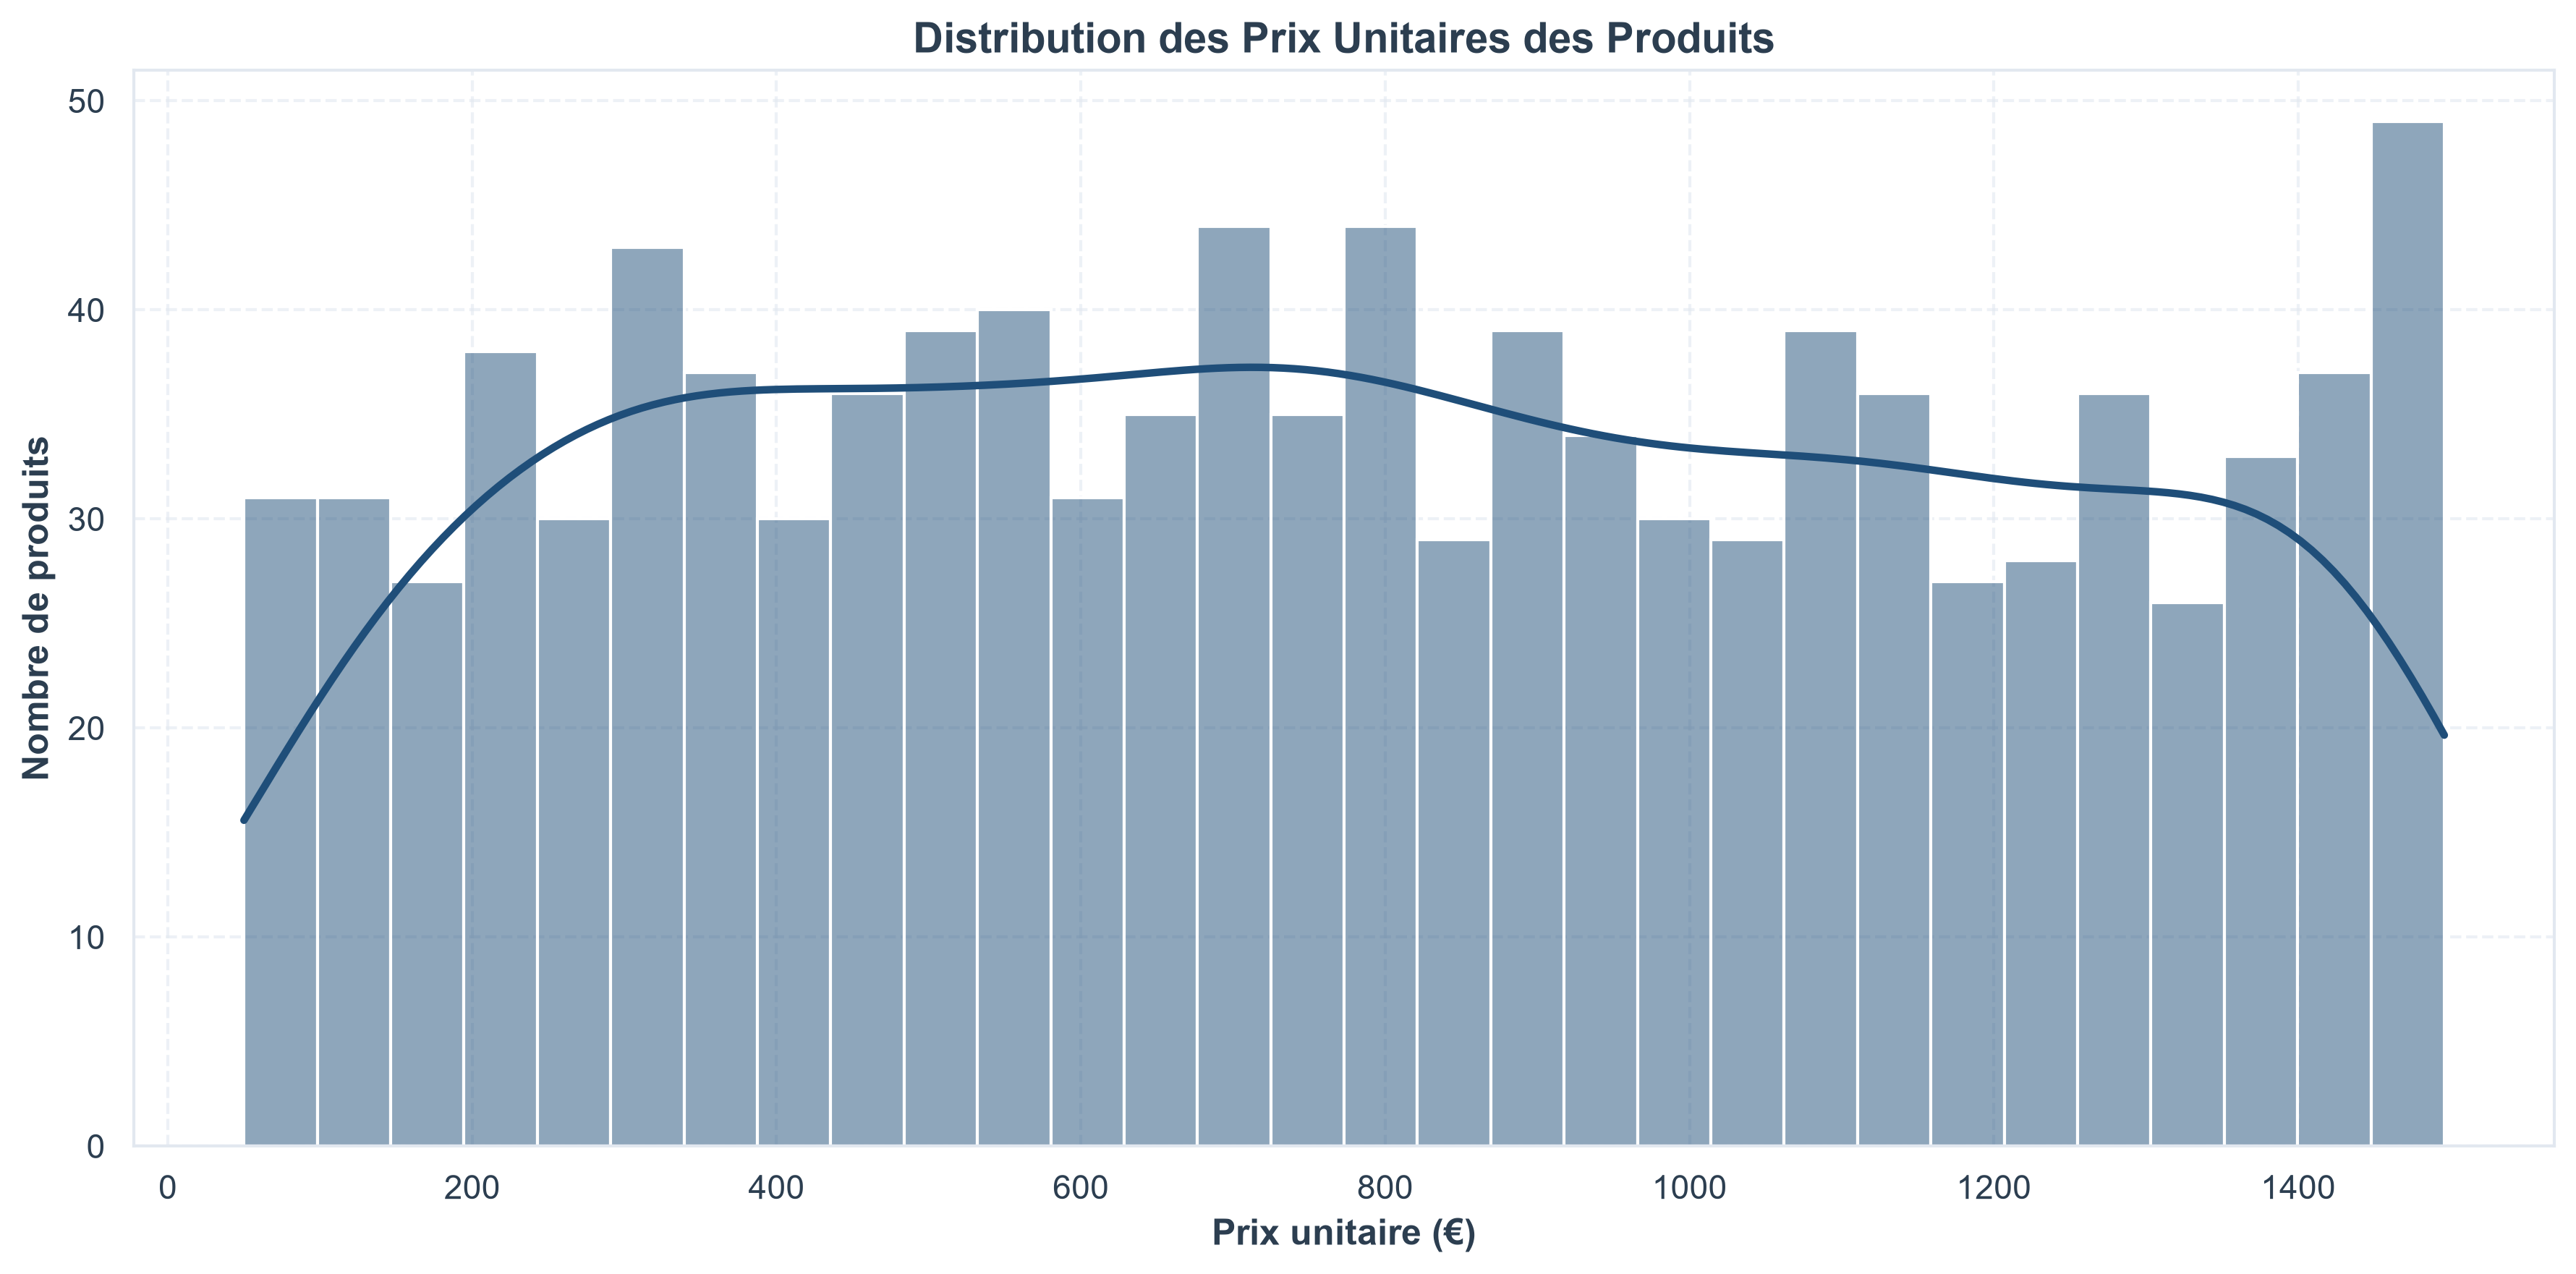

In [112]:
# Création de la figure
plt.figure()

# Tracé de l'histogramme avec la courbe de densité pour le prix unitaire
sns.histplot(
    data=Sales,
    x="UnitPrice",
    color=PRIMARY_COLOR,
    kde=True,
    bins=30
)

# Titre et labels adaptés
plt.title("Distribution des Prix Unitaires des Produits")
plt.xlabel("Prix unitaire (€)")
plt.ylabel("Nombre de produits")

plt.tight_layout()
plt.show()

### 💡 Analyse de la distribution des prix unitaires

L'histogramme des prix unitaires révèle une répartition **relativement homogène** du catalogue de produits :
* **Diversité de l'offre :** Les prix s'échelonnent de manière fluide depuis les premiers prix jusqu'aux articles haut de gamme frôlant les 1 500 €.
* **Structure du catalogue :** On observe une présence équilibrée de produits à différentes gammes de prix, ce qui explique la coexistence de petits paniers et de commandes à forte valeur (notamment dans la catégorie électronique).

### 4.6. Distribution des quantités commandées (`Quantity`)
- **Objectif** : Étudier les volumes d'achat par transaction afin de déterminer si les clients achètent principalement à l'unité ou en gros volumes.
- **Indicateur visualisé** : Fréquence des quantités d'articles commandés par transaction.

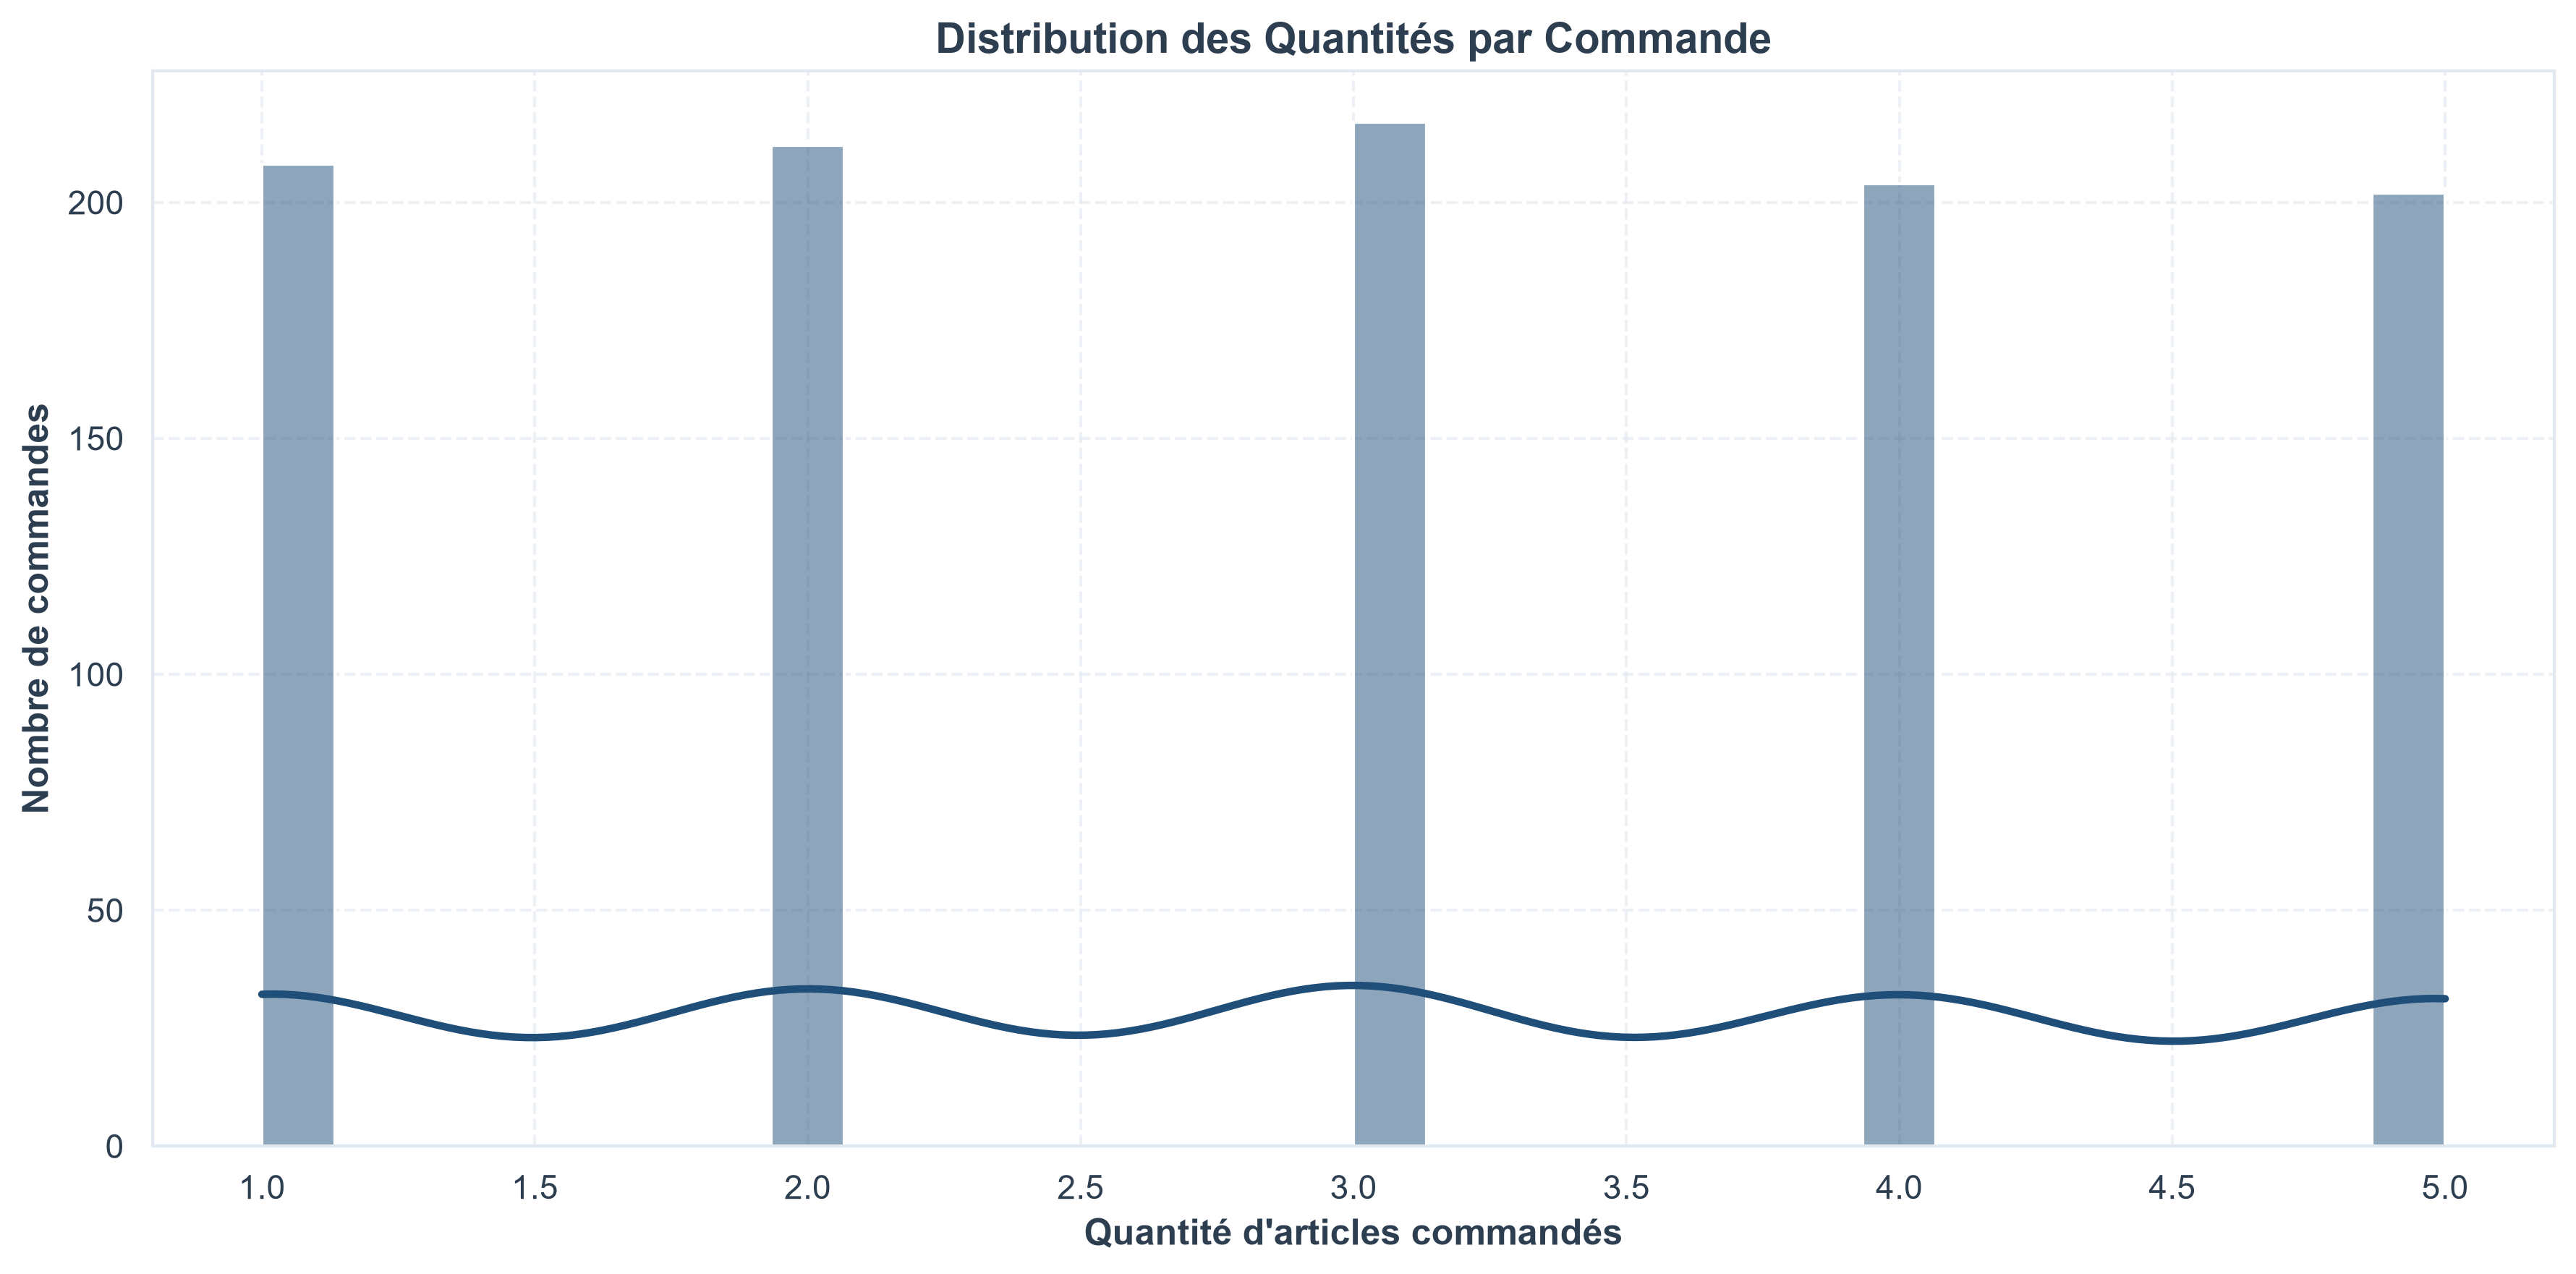

In [113]:
# Création de la figure
plt.figure()

# Tracé de l'histogramme avec la courbe de densité pour la quantité
sns.histplot(
    data=Sales,
    x="Quantity",
    color=PRIMARY_COLOR,
    kde=True,
    bins=30
)

# Titre et labels adaptés
plt.title("Distribution des Quantités par Commande")
plt.xlabel("Quantité d'articles commandés")
plt.ylabel("Nombre de commandes")

plt.tight_layout()
plt.show()

### 💡 Analyse de la distribution des quantités par commande

L'analyse des volumes d'articles par transaction met en évidence un comportement d'achat très structuré :
* **Équilibre des volumes :** Les quantités commandées par transaction se répartissent de manière très homogène sur des valeurs discrètes (allant généralement de 1 à 5 articles par commande).
* **Implication opérationnelle :** Chaque volume d'articles (qu'il s'agisse d'un achat unitaire ou de lots de 2, 3, 4, 5) représente un volume de commandes équivalent (autour de 200 transactions par niveau de quantité), confirmant l'absence de surconcentration sur une taille de panier en volume unique.